# 04 — Benchmarks, models and evaluation (steps 4–6)

**Purpose.** Compare simple ways of predicting churn with models that use the custom measures from
step 3, and judge them only on the test months (July–September 2011). Logic lives in
`src/evaluation.py` (tested in `tests/test_evaluation.py`); this notebook runs it.

The gradient boosting model is scikit-learn's `HistGradientBoostingClassifier`. It is the same kind
of model as LightGBM and handles missing values itself, but needs no extra system library.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score

from src.data import PROCESSED_DIR, load_clean
from src.evaluation import (RAW_MEASURES, bootstrap_ci, fit_predict, make_boosting, make_logistic,
                            measure_columns, precision_at)
from src.features import build_features
from src.labels import build_snapshots, split_cutoffs, valid_cutoffs

FIG = ROOT / "reports" / "figures"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.float_format", "{:,.3f}".format)

features = pd.read_parquet(PROCESSED_DIR / "features.parquet")   # written by notebook 03
MEASURES = measure_columns(features)
train_cuts, test_cuts = split_cutoffs(valid_cutoffs(90), horizon_days=90, n_test=3)
train = features[features["cutoff"].isin(train_cuts)]
test = features[features["cutoff"].isin(test_cuts)].reset_index(drop=True)
y, groups = test["churn"].to_numpy(), test["customer_id"].to_numpy()
print(f"train {len(train):,} rows (churn {train['churn'].mean():.1%}), "
      f"test {len(test):,} rows (churn {y.mean():.1%})")

train 21,243 rows (churn 64.9%), test 12,964 rows (churn 56.2%)


## 1. Benchmarks and models (steps 4 and 5)

Six ways of scoring each test customer, from simplest to most complex:

| Name | What it is |
|---|---|
| No model | Everyone gets the training churn rate (65%); no ranking at all |
| Recency rule | Longer since last purchase = more likely to churn |
| Logistic, raw | Logistic regression on recency, orders and spend (365 days) only |
| Boosting, raw | Gradient boosting on the same three raw measures |
| Logistic, all | Logistic regression on all 21 measures |
| Boosting, all | Gradient boosting on all 21 measures |

All models learn only from the training cutoffs (December 2010 to April 2011). Churn is the majority
outcome (56–65%), so no class weighting is used.

In [2]:
scores = {
    "No model": np.full(len(test), train["churn"].mean()),
    "Recency rule": test["recency_days"].to_numpy(float),
    "Logistic, raw": fit_predict(make_logistic, RAW_MEASURES, train, test),
    "Boosting, raw": fit_predict(make_boosting, RAW_MEASURES, train, test),
    "Logistic, all": fit_predict(make_logistic, MEASURES, train, test),
    "Boosting, all": fit_predict(make_boosting, MEASURES, train, test),
}

## 2. How good are the predictions? (step 6)

* **PR-AUC** (average precision): how well the score ranks churners above non-churners, where a
  random ranking scores the churn rate (0.56).
* **Precision in the top 10% / 20%:** churn rate among the customers flagged as most at risk.
* **Brier score:** how close the predicted probabilities are to what happened (lower is better);
  only for scores that are probabilities.

The 95% intervals come from resampling whole customers 1,000 times, because the same customer
appears at several test cutoffs.

In [3]:
def summarize(name, s):
    is_prob = name != "Recency rule"
    return {
        "PR-AUC": average_precision_score(y, s),
        "PR-AUC 95% CI": "{:.3f} to {:.3f}".format(*bootstrap_ci(
            lambda ix: average_precision_score(y[ix], s[ix]), groups)),
        "ROC AUC": roc_auc_score(y, s) if name != "No model" else 0.5,
        "top 10%": precision_at(y, s, 0.10) if name != "No model" else y.mean(),
        "top 20%": precision_at(y, s, 0.20) if name != "No model" else y.mean(),
        "Brier": brier_score_loss(y, s) if is_prob else np.nan,
    }

results = pd.DataFrame({name: summarize(name, s) for name, s in scores.items()}).T
results

,PR-AUC,PR-AUC 95% CI,ROC AUC,top 10%,top 20%,Brier
No model,0.562,0.550 to 0.576,0.500,0.562,0.562,0.254
Recency rule,0.738,0.721 to 0.753,0.724,0.778,0.767,NaN
"Logistic, raw",0.788,0.773 to 0.802,0.781,0.841,0.831,0.199
"Boosting, raw",0.787,0.771 to 0.802,0.780,0.837,0.825,0.197
"Logistic, all",0.792,0.777 to 0.807,0.783,0.857,0.840,0.190
"Boosting, all",0.794,0.779 to 0.808,0.781,0.861,0.840,0.192


## 3. Do the custom measures help?

Paired comparisons on the same resampled customers. A difference whose interval includes zero is
not established by this data.

In [4]:
def difference(a, b, metric):
    sa, sb = scores[a], scores[b]
    point = metric(y, sa) - metric(y, sb)
    lo, hi = bootstrap_ci(lambda ix: metric(y[ix], sa[ix]) - metric(y[ix], sb[ix]), groups)
    return f"{point:+.3f} ({lo:+.3f} to {hi:+.3f})"

top10 = lambda yy, s: precision_at(yy, s, 0.10)
pairs = [("Boosting, all", "Boosting, raw"), ("Logistic, all", "Logistic, raw"),
         ("Boosting, all", "Logistic, raw"), ("Logistic, raw", "Recency rule")]
pd.DataFrame({f"{a} vs {b}": {"PR-AUC difference": difference(a, b, average_precision_score),
                               "top-10% precision difference": difference(a, b, top10)}
              for a, b in pairs}).T

,PR-AUC difference,top-10% precision difference
"Boosting, all vs Boosting, raw",+0.007 (-0.002 to +0.016),+0.024 (-0.004 to +0.049)
"Logistic, all vs Logistic, raw",+0.004 (-0.003 to +0.012),+0.016 (-0.002 to +0.040)
"Boosting, all vs Logistic, raw",+0.006 (-0.004 to +0.016),+0.020 (-0.006 to +0.051)
"Logistic, raw vs Recency rule",+0.050 (+0.041 to +0.059),+0.063 (+0.037 to +0.086)


## 4. Stability across the three test months

In [5]:
by_month = {}
for cutoff, rows in test.groupby("cutoff").groups.items():
    by_month[cutoff.strftime("%b %Y")] = {name: average_precision_score(y[rows], scores[name][rows])
                                          for name in ["Recency rule", "Logistic, raw", "Boosting, all"]}
    by_month[cutoff.strftime("%b %Y")]["churn rate"] = y[rows].mean()
pd.DataFrame(by_month).T

,Recency rule,"Logistic, raw","Boosting, all",churn rate
Jul 2011,0.802,0.839,0.841,0.614
Aug 2011,0.751,0.802,0.812,0.569
Sep 2011,0.679,0.732,0.728,0.505


## 5. Calibration: do the predicted chances match what happened?

Test customers are grouped by predicted churn chance (Boosting, all). Training months had more churn
(65%) than test months (56%), so the model is expected to over-predict a little.

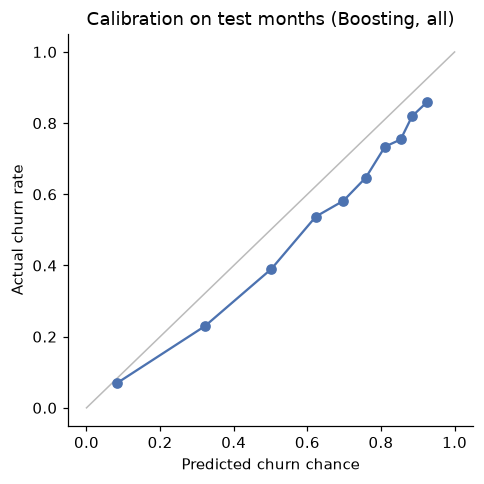

,predicted,actual,gap
0,0.084,0.070,-0.014
1,0.322,0.230,-0.092
2,0.502,0.390,-0.112
3,0.623,0.537,-0.086
4,0.698,0.582,-0.116
5,0.759,0.647,-0.112
6,0.811,0.734,-0.077
7,0.853,0.754,-0.099
8,0.884,0.819,-0.065
9,0.926,0.860,-0.066


In [6]:
p = scores["Boosting, all"]
bins = pd.qcut(p, 10, labels=False, duplicates="drop")
calib = pd.DataFrame({"predicted": p, "actual": y}).groupby(bins).mean()

fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.plot([0, 1], [0, 1], color="#BBBBBB", lw=1)
ax.plot(calib["predicted"], calib["actual"], marker="o", color="#4C72B0")
ax.set_xlabel("Predicted churn chance"); ax.set_ylabel("Actual churn rate")
ax.set_title("Calibration on test months (Boosting, all)")
fig.tight_layout(); fig.savefig(FIG / "04_calibration.png"); plt.show()
calib.assign(gap=calib["actual"] - calib["predicted"])

## 6. Which measures matter most?

Permutation importance on the test months: how much PR-AUC drops when one measure is shuffled.
This shows what the model relies on for prediction, not what causes churn.

In [7]:
model = make_boosting().fit(train[MEASURES], train["churn"])
imp = permutation_importance(model, test[MEASURES], y, scoring="average_precision",
                             n_repeats=5, random_state=0)
pd.Series(imp.importances_mean, index=MEASURES).sort_values(ascending=False).head(10).rename("PR-AUC drop")

spend_365d           0.017
recency_days         0.014
gap_std_days         0.011
orders_365d          0.010
overdue_ratio        0.009
median_gap_days      0.009
tenure_days          0.004
products_per_order   0.003
spend_180d           0.003
avg_order_value      0.002
Name: PR-AUC drop, dtype: float64

## 7. Robustness checks (decided before modelling)

The same comparison (Boosting, all vs Logistic, raw) under the other churn definitions from step 2,
and for customers active in the last 6 months only (the to-do item about the active window).

In [8]:
data = load_clean()

def compare(train_rows, test_rows, label):
    yy, gg = test_rows["churn"].to_numpy(), test_rows["customer_id"].to_numpy()
    simple = fit_predict(make_logistic, RAW_MEASURES, train_rows, test_rows)
    full = fit_predict(make_boosting, MEASURES, train_rows, test_rows)
    diff = lambda ix: average_precision_score(yy[ix], full[ix]) - average_precision_score(yy[ix], simple[ix])
    lo, hi = bootstrap_ci(diff, gg, n_boot=500)
    return {"check": label, "test churn rate": yy.mean(),
            "PR-AUC, Logistic raw": average_precision_score(yy, simple),
            "PR-AUC, Boosting all": average_precision_score(yy, full),
            "difference (95% CI)": f"{diff(np.arange(len(yy))):+.3f} ({lo:+.3f} to {hi:+.3f})"}

checks = []
for n in (60, 120):
    cuts = valid_cutoffs(n)
    tr_c, te_c = split_cutoffs(cuts, horizon_days=n, n_test=3)
    f_n = build_features(data.purchases, data.cancellations, build_snapshots(data.purchases, cuts, horizon_days=n))
    checks.append(compare(f_n[f_n["cutoff"].isin(tr_c)], f_n[f_n["cutoff"].isin(te_c)].reset_index(drop=True),
                          f"{n}-day window"))
recent = lambda df: df[df["recency_days"] <= 182].reset_index(drop=True)
checks.append(compare(recent(train), recent(test), "90-day window, active in last 6 months"))
pd.DataFrame(checks).set_index("check")

,test churn rate,"PR-AUC, Logistic raw","PR-AUC, Boosting all",difference (95% CI)
check,,,,
60-day window,0.621,0.819,0.830,+0.010 (+0.002 to +0.017)
120-day window,0.523,0.771,0.771,+0.001 (-0.011 to +0.011)
"90-day window, active in last 6 months",0.442,0.692,0.696,+0.003 (-0.011 to +0.015)


In [9]:
# Test-month predictions for the profit analysis (notebook 05)
out = test[["customer_id", "cutoff", "churn", "spend_365d", "recency_days"]].copy()
for name in ["Logistic, raw", "Boosting, all"]:
    out[f"p_{name.split(',')[0].lower()}_{name.split(', ')[1]}"] = scores[name]
out["train_churn_rate"] = train["churn"].mean()
out.to_parquet(PROCESSED_DIR / "test_predictions.parquet", index=False)
out.columns.tolist()

['customer_id',
 'cutoff',
 'churn',
 'spend_365d',
 'recency_days',
 'p_logistic_raw',
 'p_boosting_all',
 'train_churn_rate']

## 8. Findings

1. **Models clearly beat simple rules.** Logistic regression on recency, orders and spend reaches a
   PR-AUC of 0.788 against 0.738 for the recency rule (+0.050, 95% CI +0.041 to +0.059), and 84% of
   its top-10% flagged customers churn, against 78% for the rule.
2. **The custom measures add a little, but this data cannot confirm it.** Boosting on all 21 measures
   beats boosting on the three raw ones by +0.007 PR-AUC (−0.002 to +0.016) and +2.4 points of
   top-10% precision (−0.4 to +4.9). The robustness checks agree: only the 60-day window shows a
   clear gain; the 120-day window and the 6-month active group do not. By the rule fixed in step 2
   (a finding counts only if it holds under every definition), the answer to question 1 is **no, not
   with this data**: recency, frequency and spend carry nearly all of the signal.
3. **Results are stable across the test months**, though every method scores lower in September,
   when fewer customers churn because of the holiday season.
4. **Predictions are 7–12 points too high** because the training months had more churn (65%) than
   the test months (56%). This does not affect rankings, but it makes the expected-value rule in
   notebook 05 contact somewhat more customers than it should.
5. **The model leans most on** spend, recency, how irregular a customer's ordering is, order count
   and the overdue ratio. This shows what predicts churn, not what causes it.